# AIE322 - Advanced Machine Learning
## Assignment: Predicting Customer Churn in E-Commerce



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy import sparse

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

warnings.filterwarnings("ignore")
sns.set_theme(style="ticks", palette="Set2")
plt.rcParams["figure.facecolor"] = "#f7f9fc"
plt.rcParams["axes.facecolor"] = "#ffffff"
plt.rcParams["axes.edgecolor"] = "#d6deea"
plt.rcParams["grid.color"] = "#e7edf5"
plt.rcParams["grid.alpha"] = 0.65
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [ ]:
# Upload the Excel dataset from your computer into this Colab session.
from google.colab import files
from pathlib import Path

uploaded = files.upload()
excel_files = [name for name in uploaded if name.lower().endswith((".xlsx", ".xls"))]
if not excel_files:
    raise FileNotFoundError("No Excel file was uploaded. Please upload the E Commerce Dataset.xlsx file.")

# Use the first uploaded Excel workbook.
DATA_PATH = excel_files[0]
print("Selected dataset:", DATA_PATH)


Saving E Commerce Dataset.xlsx to E Commerce Dataset.xlsx
Selected dataset: E Commerce Dataset.xlsx


In [ ]:
# Read the expected worksheet and verify the required column.
workbook = pd.ExcelFile(DATA_PATH)
if "E Comm" not in workbook.sheet_names:
    raise ValueError(
        f"Expected worksheet 'E Comm' was not found. Available worksheets: {workbook.sheet_names}"
    )

df_raw = pd.read_excel(DATA_PATH, sheet_name="E Comm")
if "CustomerID" not in df_raw.columns:
    raise KeyError("The dataset is missing the required 'CustomerID' column.")

print("Dataset shape:", df_raw.shape)
df = df_raw.drop(columns=["CustomerID"])
display(df.head())
df.info()


Dataset shape: (5630, 20)


,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Churn                        5630 non-null   int64  
 1   Tenure                       5366 non-null   float64
 2   PreferredLoginDevice         5630 non-null   object 
 3   CityTier                     5630 non-null   int64  
 4   WarehouseToHome              5379 non-null   float64
 5   PreferredPaymentMode         5630 non-null   object 
 6   Gender                       5630 non-null   object 
 7   HourSpendOnApp               5375 non-null   float64
 8   NumberOfDeviceRegistered     5630 non-null   int64  
 9   PreferedOrderCat             5630 non-null   object 
 10  SatisfactionScore            5630 non-null   int64  
 11  MaritalStatus                5630 non-null   object 
 12  NumberOfAddress              5630 non-null   int64  
 13  Complain          

## 1.2 Standardize category labels and inspect data quality
* **Category labels:** several values have alternate spellings (`Phone`/`Mobile Phone`, `CC`/`Credit Card`, `COD`/`Cash on Delivery`, `Mobile`/`Mobile Phone`). These are unified using fixed replacements, not learned from the target.
* **Repeated records:** after removing `CustomerID`, exact duplicate rows are deleted before the train/test split to prevent overlap between the two sets.

In [ ]:
df = df.replace({"Phone": "Mobile Phone", "Mobile": "Mobile Phone", "CC": "Credit Card", "COD": "Cash on Delivery"})

print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

missing = df.isna().sum()
print("\nMissing values:")
print(missing[missing > 0])

cols = ["Tenure", "WarehouseToHome", "HourSpendOnApp", "OrderAmountHikeFromlastYear",
        "CouponUsed", "OrderCount", "DaySinceLastOrder", "CashbackAmount", "NumberOfAddress"]
q1, q3 = df[cols].quantile(0.25), df[cols].quantile(0.75)
iqr = q3 - q1
outliers = ((df[cols] < q1 - 1.5 * iqr) | (df[cols] > q3 + 1.5 * iqr)).sum()
print("Outliers per column (IQR rule):")
print(outliers)

Duplicate rows: 557
Shape after removing duplicates: (5073, 19)

Missing values:
Tenure                         231
WarehouseToHome                221
HourSpendOnApp                 230
OrderAmountHikeFromlastYear    252
CouponUsed                     210
OrderCount                     243
DaySinceLastOrder              288
dtype: int64
Outliers per column (IQR rule):
Tenure                           4
WarehouseToHome                  2
HourSpendOnApp                   6
OrderAmountHikeFromlastYear     29
CouponUsed                     610
OrderCount                     673
DaySinceLastOrder               57
CashbackAmount                 382
NumberOfAddress                  4
dtype: int64


**Outliers** are flagged for inspection only. They are retained because they may represent genuine customer behavior and tree-based methods are generally less sensitive to them.

## 1.3 Visual and statistical exploration (EDA)

Churn
0    4232
1     841
Name: count, dtype: int64
Churn
0    0.8342
1    0.1658
Name: proportion, dtype: float64


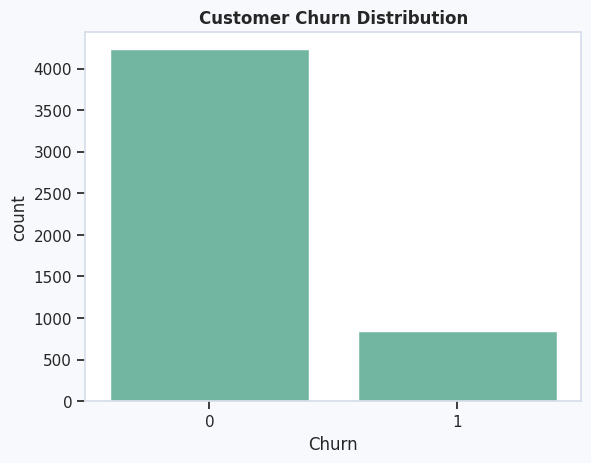

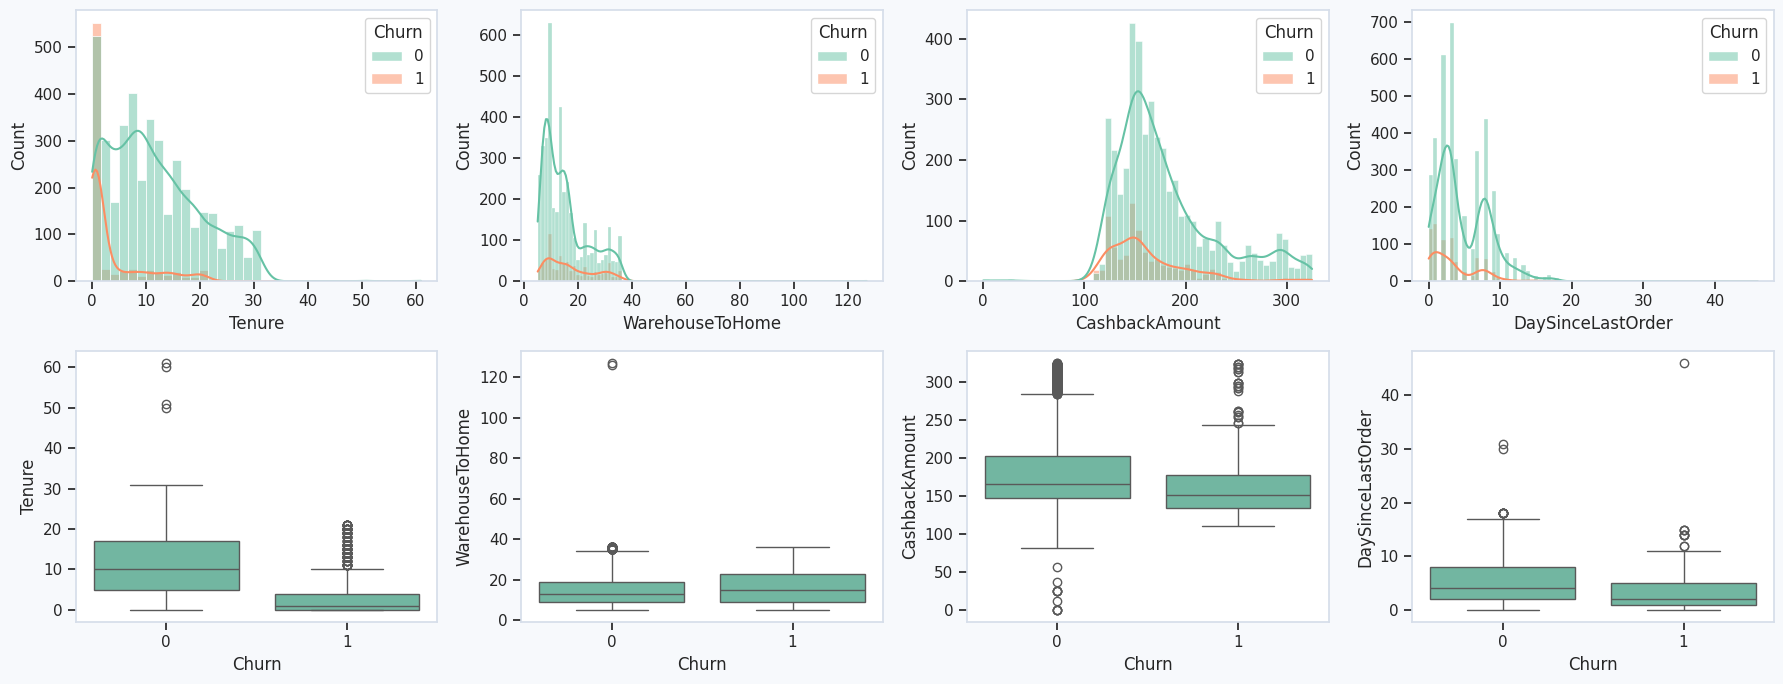

       Tenure  WarehouseToHome  CashbackAmount  DaySinceLastOrder
Churn                                                            
0        10.0             13.0          166.32                4.0
1         1.0             15.0          151.00                2.0


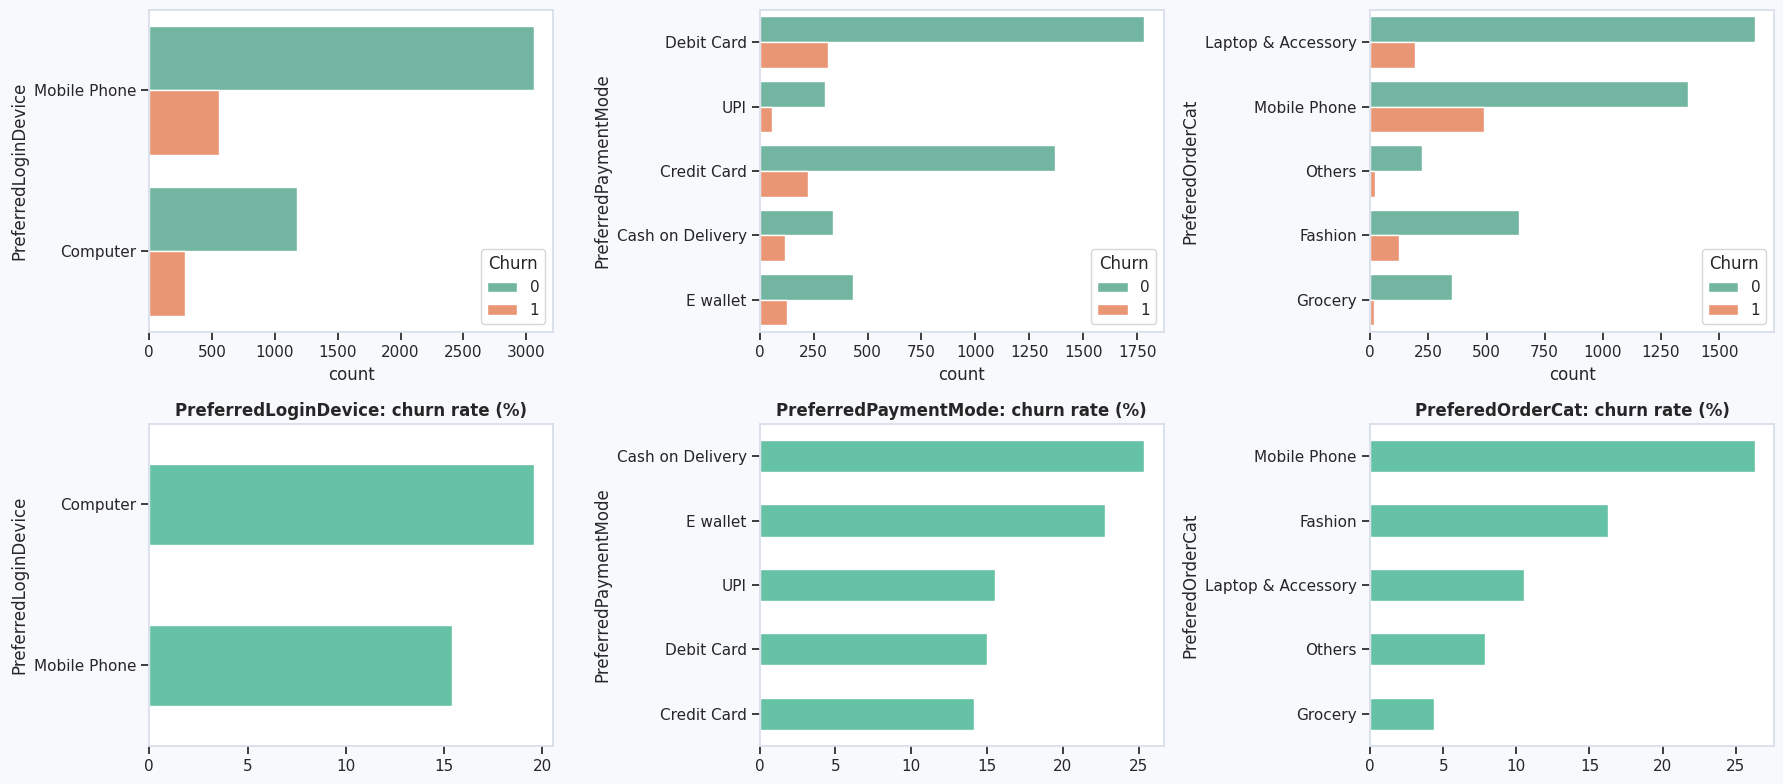

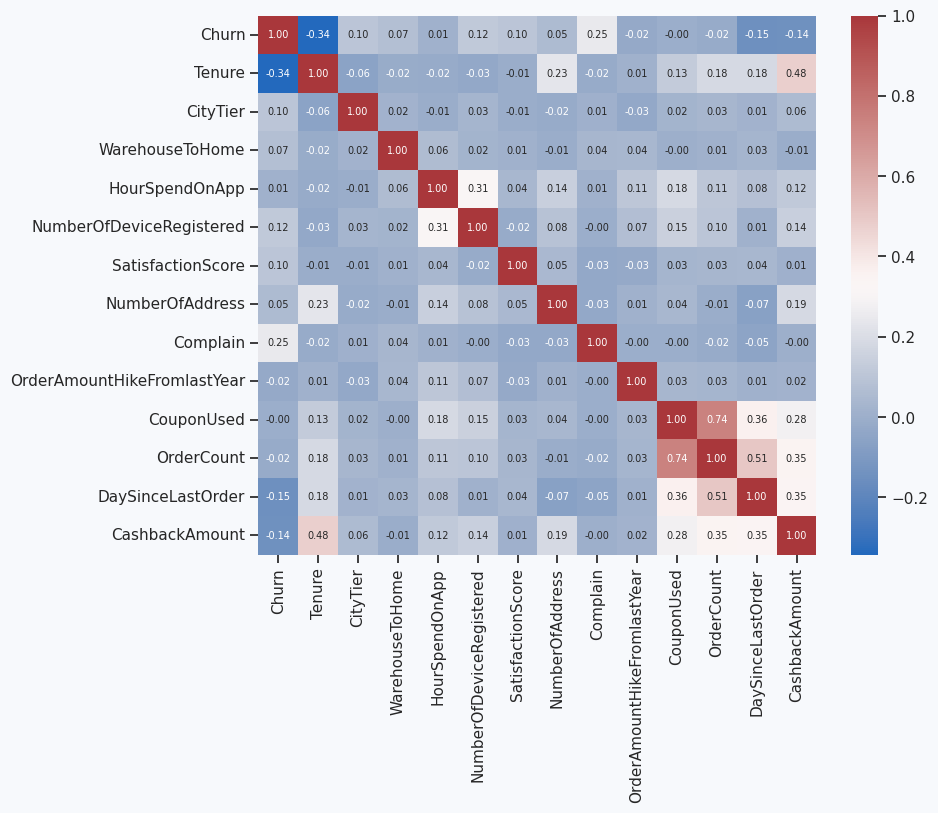

In [ ]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(4))

sns.countplot(x="Churn", data=df)
plt.title("Customer Churn Distribution")
plt.show()

key_num = ["Tenure", "WarehouseToHome", "CashbackAmount", "DaySinceLastOrder"]

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(key_num):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, ax=axes[0, i])
    sns.boxplot(data=df, x="Churn", y=col, ax=axes[1, i])
plt.tight_layout()
plt.show()

print(df.groupby("Churn")[key_num].median())

key_cat = ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for i, col in enumerate(key_cat):
    sns.countplot(data=df, y=col, hue="Churn", ax=axes[0, i])
    rate = df.groupby(col)["Churn"].mean() * 100
    rate.sort_values().plot(kind="barh", ax=axes[1, i], title=col + ": churn rate (%)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(df.select_dtypes("number").corr(), cmap="vlag", annot=True, fmt=".2f", annot_kws={"size": 7})
plt.show()

**Key observations from the dataset**
* **Imbalanced target:** only about 17 % of customers churn, so accuracy alone can be misleading. We also report Precision, Recall and F1.
* **Customers who left** have much lower `Tenure` and `CashbackAmount`, a larger `WarehouseToHome`, and a lower `DaySinceLastOrder`.
* **Churn is higher** for the *Mobile Phone* category, *Cash on Delivery* and *E wallet*, and lowest for *Grocery*.
* About 4-6 % of values are missing in some numeric columns. We fill them with the median inside the pipeline.

## 1.4 Create training and testing sets

In [ ]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

Train: (4058, 18) | Test: (1015, 18)
Churn rate train: 0.1658 | test: 0.1655


### Why set `random_state` during the split?

`train_test_split` randomizes row assignment. Setting a fixed `random_state` makes the split reproducible, which provides:
* **Reproducibility:** consistent train/test rows between runs.
* **Comparable evaluation:** each model is tested using the same split.
* **Simpler troubleshooting:** results can be recreated when checking the code.

`stratify=y` also keeps the same churn ratio in both sets.

---
# Part 2 - Preprocessing Pipelines
## 2.1 Separate numeric features from categorical features

In [ ]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
Categorical: ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']


## 2.2 Numeric preprocessing and imputer statistics

In [ ]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

imp = SimpleImputer(strategy="median")
imp.fit(X_train[num_cols])
print(pd.Series(imp.statistics_, index=num_cols))
print("has statistics_:", hasattr(imp, "statistics_"))
print("has median_    :", hasattr(imp, "median_"))

Tenure                           9.000
CityTier                         1.000
WarehouseToHome                 13.000
HourSpendOnApp                   3.000
NumberOfDeviceRegistered         4.000
SatisfactionScore                3.000
NumberOfAddress                  3.000
Complain                         0.000
OrderAmountHikeFromlastYear     15.000
CouponUsed                       1.000
OrderCount                       2.000
DaySinceLastOrder                3.000
CashbackAmount                 163.845
dtype: float64
has statistics_: True
has median_    : False


**Why is the attribute called `.statistics_` instead of `.median_`?** `SimpleImputer` has several strategies (mean, median, most_frequent, constant). In all of them it only stores one fill value per column, so scikit-learn uses one common name: **`statistics_`**. This way you can change the strategy without changing the code (`hasattr(imp, 'median_')` is `False` above).

## 2.3 Encode categories and examine sparse output

In [ ]:
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

ohe = OneHotEncoder()
encoded = ohe.fit_transform(X_train[cat_cols])
print("Output type:", type(encoded))
print("Is sparse:", sparse.issparse(encoded))
print("Shape:", encoded.shape, "| non-zero values:", encoded.nnz)

Output type: <class 'scipy.sparse._csr.csr_matrix'>
Is sparse: True
Shape: (4058, 17) | non-zero values: 20290


**Why a sparse matrix?** One-hot encoding mostly produces zeros, with a single active value for each original categorical feature. Sparse storage keeps only non-zero entries, saving **memory** and often improving efficiency. `.toarray()` or `sparse_output=False` can be used when a dense array is needed.

## 2.4 Combine preprocessing with the model pipeline

In [ ]:
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

def make_pipe(clf):
    return Pipeline([("prep", preprocessor), ("clf", clf)])

master = make_pipe(LogisticRegression(max_iter=2000, random_state=42))
master.fit(X_train, y_train)
print("Train accuracy:", round(master.score(X_train, y_train), 4))
print("Test accuracy :", round(master.score(X_test, y_test), 4))
display(master)

Train accuracy: 0.8935
Test accuracy : 0.8798


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['Tenure', 'CityTier',
                                                   'WarehouseToHome',
                                                   'HourSpendOnApp',
                                                   'NumberOfDeviceRegistered',
                                                   'SatisfactionScore',
                                                   'NumberOfAddress',
                                                   'Complain',
                                                   'OrderAmountHikeFromlastYear',
                                                   'CouponUsed', 'OrderCount',
                                                   'DaySinceLastOrder',
                                                   'CashbackAmount']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['PreferredLoginDevice',
                                                   'PreferredPaymentMode',
                                                   'Gender', 'PreferedOrderCat',
                                                   'MaritalStatus'])])),
                ('clf', LogisticRegression(max_iter=2000, random_state=42))])

### What does `pipeline.fit(X_train, y_train)` do?

* **Transformers** (the `ColumnTransformer` and the imputers, scaler and encoder inside it) run **`fit_transform`**: each one learns from the training data only (medians, min/max, categories) and passes its result to the next step.
* The **final model** runs **`fit` only**: it learns from the fully transformed training data.

When we call `predict` or `score`, the transformers only run **`transform`** using what they learned from the training set. So the test data never affects preprocessing (no leakage).

---
# Part 3 - Model Complexity, Bias/Variance, and Regularization
A shared evaluation function is used to collect the metrics for each model.

In [ ]:
results = []

def evaluate(name, model):
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    row = {
        "model": name,
        "train_acc": accuracy_score(y_train, pred_train),
        "test_acc": accuracy_score(y_test, pred_test),
        "precision": precision_score(y_test, pred_test),
        "recall": recall_score(y_test, pred_test),
        "f1": f1_score(y_test, pred_test),
    }
    if hasattr(model, "predict_proba"):
        row["roc_auc"] = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    results.append(row)
    return row

def table(rows):
    return pd.DataFrame(rows).set_index("model").round(4)

## 3.1 Compare underfitting and overfitting
Three tree sizes are evaluated: a shallow tree, a moderate-depth tree, and an unrestricted tree.

,train_acc,test_acc,precision,recall,f1,roc_auc
model,,,,,,
Tree depth=1,0.8428,0.8276,0.4844,0.6488,0.5547,0.7559
Tree depth=6,0.9165,0.8857,0.7167,0.5119,0.5972,0.8896
Tree depth=None,1.0000,0.9557,0.8639,0.8690,0.8665,0.9209


Majority-class accuracy: 0.8345


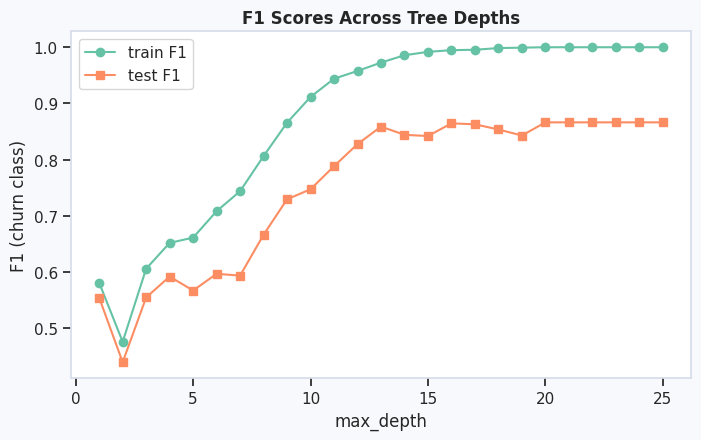

In [ ]:
rows = []
for name, depth in [("Tree depth=1", 1), ("Tree depth=6", 6), ("Tree depth=None", None)]:
    tree = make_pipe(DecisionTreeClassifier(max_depth=depth, random_state=42))
    tree.fit(X_train, y_train)
    rows.append(evaluate(name, tree))

display(table(rows))
print("Majority-class accuracy:", round(1 - y_test.mean(), 4))

depths = range(1, 26)
train_f1, test_f1 = [], []
for d in depths:
    tree = make_pipe(DecisionTreeClassifier(max_depth=d, random_state=42))
    tree.fit(X_train, y_train)
    train_f1.append(f1_score(y_train, tree.predict(X_train)))
    test_f1.append(f1_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(8, 4.5))
plt.plot(depths, train_f1, "o-", label="train F1")
plt.plot(depths, test_f1, "s-", label="test F1")
plt.xlabel("max_depth")
plt.ylabel("F1 (churn class)")
plt.title("F1 Scores Across Tree Depths")
plt.legend()
plt.show()

### How are bias and variance affected by model complexity?

* **Bias goes down:** a flexible model can learn more complex patterns.
* **Variance goes up:** it also starts learning the noise in the training data, so the gap between train and test score grows.

In theory, the test error is U-shaped. Here, shallow trees underfit, the training F1 reaches 1.0 as depth grows, and the test F1 rises then levels off (about 0.85) because the churn pattern is strongly non-linear. The remaining train-test gap is the variance that bagging reduces in Part 4.

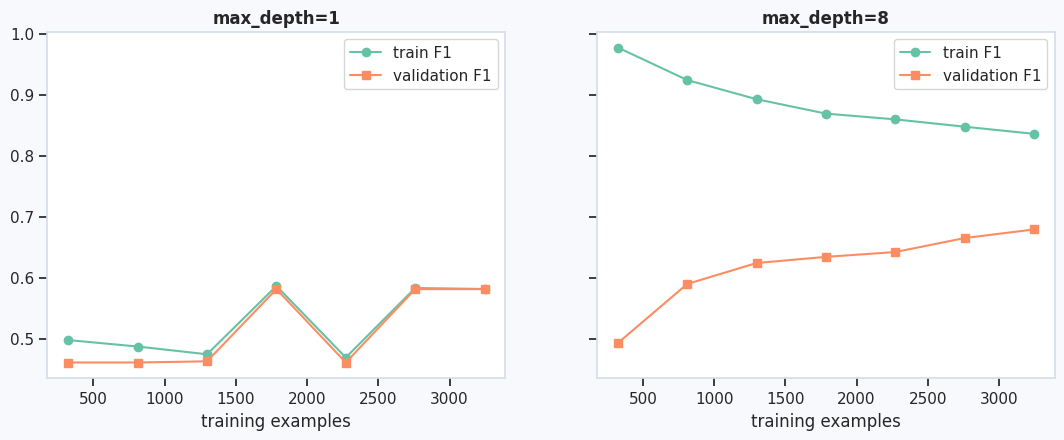

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, depth in zip(axes, [1, 8]):
    tree = make_pipe(DecisionTreeClassifier(max_depth=depth, random_state=42))
    sizes, train_sc, val_sc = learning_curve(tree, X_train, y_train, train_sizes=np.linspace(0.1, 1, 7),
                                             cv=5, scoring="f1", n_jobs=-1, shuffle=True, random_state=42)
    ax.plot(sizes, train_sc.mean(axis=1), "o-", label="train F1")
    ax.plot(sizes, val_sc.mean(axis=1), "s-", label="validation F1")
    ax.set_title("max_depth=" + str(depth))
    ax.set_xlabel("training examples")
    ax.legend()
plt.show()

### Why can model complexity help where additional data does not?

Underfitting means the model is too simple, even for the training data (high bias).
* **More data:** the learning curves of the depth-1 tree stay low and flat and reach the same limit, because the problem is the model, not the amount of data.
* **More complexity:** the depth-8 tree can use many features and thresholds, so its validation F1 is clearly higher than the depth-1 tree.

## 3.2 Logistic regression regularization
L2, L1, and Elastic Net are tested with `solver="saga"` and `max_iter=2000` on scaled features, alongside an unregularized baseline.

,train_acc,test_acc,precision,recall,f1,roc_auc,zero_coefs,sum|coef|
model,,,,,,,,
LogReg No penalty,0.8953,0.8828,0.7094,0.4940,0.5825,0.8748,0,51.2069
LogReg L2,0.8935,0.8788,0.7419,0.4107,0.5287,0.8640,0,33.0840
LogReg L1,0.8970,0.8847,0.7383,0.4702,0.5745,0.8722,3,42.2287
LogReg ElasticNet,0.8938,0.8828,0.7475,0.4405,0.5543,0.8675,4,35.8294


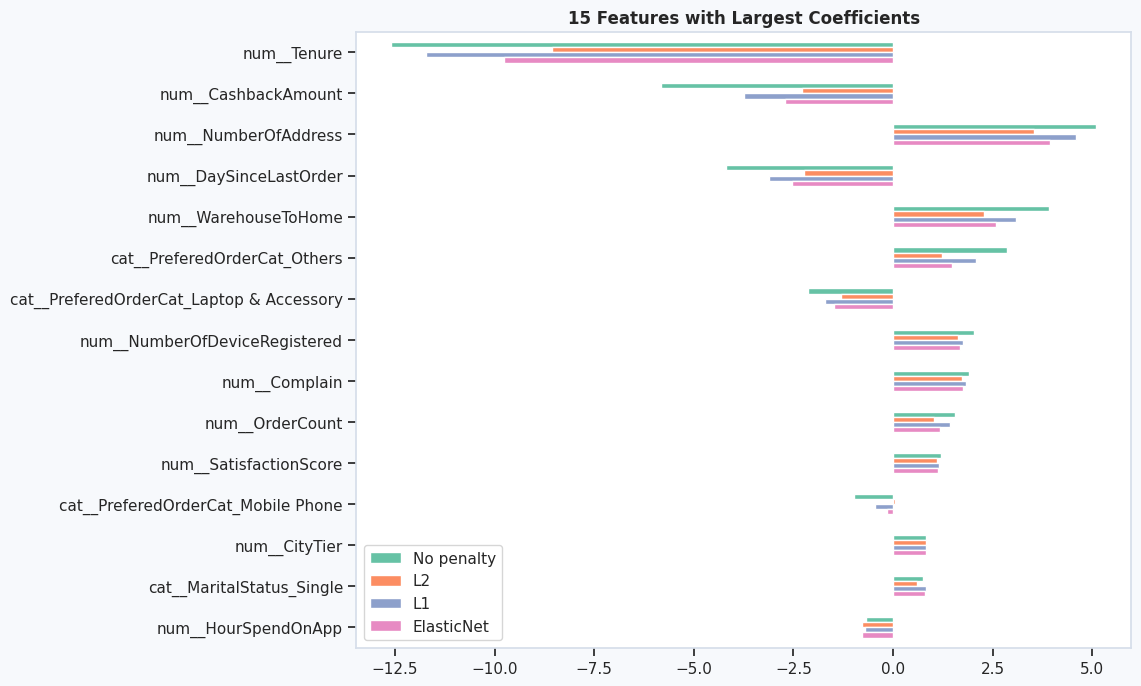

,L2 nonzero,L2 F1,L1 nonzero,L1 F1,ElasticNet nonzero,ElasticNet F1
0.001000,30,0.000,0,0.000,0,0.000
0.003162,30,0.000,0,0.000,1,0.000
0.010000,30,0.123,3,0.000,8,0.000
0.031623,30,0.287,10,0.317,19,0.230
0.100000,30,0.397,18,0.486,25,0.426
0.316228,30,0.469,23,0.530,27,0.504
1.000000,30,0.529,27,0.575,26,0.554
3.162278,30,0.571,27,0.582,28,0.569
10.000000,30,0.581,27,0.582,30,0.589


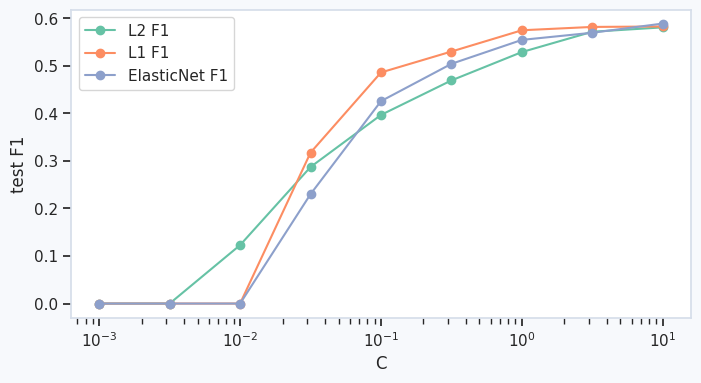

In [ ]:
penalties = {
    "No penalty": dict(penalty=None),
    "L2": dict(penalty="l2"),
    "L1": dict(penalty="l1"),
    "ElasticNet": dict(penalty="elasticnet", l1_ratio=0.5),
}

rows, coefs = [], {}
for name, params in penalties.items():
    model = make_pipe(LogisticRegression(solver="saga", max_iter=2000, random_state=42, **params))
    model.fit(X_train, y_train)
    coef = model.named_steps["clf"].coef_.ravel()
    coefs[name] = coef
    row = evaluate("LogReg " + name, model)
    row["zero_coefs"] = int((np.abs(coef) < 1e-8).sum())
    row["sum|coef|"] = np.abs(coef).sum()
    rows.append(row)

display(table(rows))

feature_names = model.named_steps["prep"].get_feature_names_out()
coef_df = pd.DataFrame(coefs, index=feature_names)
top = coef_df["No penalty"].abs().nlargest(15).index
coef_df.loc[top].plot(kind="barh", figsize=(10, 8))
plt.gca().invert_yaxis()
plt.title("15 Features with Largest Coefficients")
plt.show()

Cs = np.logspace(-3, 1, 9)
sweep = pd.DataFrame(index=Cs)
for name, params in list(penalties.items())[1:]:
    nonzero, f1s = [], []
    for C in Cs:
        m = make_pipe(LogisticRegression(solver="saga", max_iter=2000, C=C, random_state=42, **params))
        m.fit(X_train, y_train)
        nonzero.append((np.abs(m.named_steps["clf"].coef_) > 1e-8).sum())
        f1s.append(f1_score(y_test, m.predict(X_test)))
    sweep[name + " nonzero"] = nonzero
    sweep[name + " F1"] = f1s

display(sweep.round(3))
sweep.filter(like="F1").plot(logx=True, marker="o", figsize=(8, 4))
plt.xlabel("C")
plt.ylabel("test F1")
plt.show()

**Reading the regularization results**
* **L2 (Ridge):** makes all coefficients smaller but keeps every feature.
* **L1 (Lasso):** makes coefficients smaller and sets some exactly to 0 (it removes features).
* **Elastic Net:** a mix of both.

All penalties reduce `sum|coef|` compared with the no-penalty model. At `C = 1` the test scores are similar, because the model is not badly overfit. A very small `C` shrinks everything too much and underfits (F1 goes to 0). Linear models are limited mainly by bias, so regularization helps very little here.

---
# Part 4 - Ensemble Methods
## 4.1 Bagging, Pasting, and the out-of-bag (OOB) estimate
Both methods use 200 trees; they differ in the `bootstrap` setting. `max_samples=0.8` also varies the subset used by each Pasting model.

In [ ]:
bag = make_pipe(BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42), n_estimators=200,
                                  max_samples=0.8, bootstrap=True, oob_score=True, n_jobs=-1, random_state=42))
paste = make_pipe(BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42), n_estimators=200,
                                    max_samples=0.8, bootstrap=False, n_jobs=-1, random_state=42))
bag.fit(X_train, y_train)
paste.fit(X_train, y_train)

rows = [evaluate("Bagging", bag), evaluate("Pasting", paste)]
display(table(rows))

print("OOB score    :", round(bag.named_steps["clf"].oob_score_, 4))
print("Test accuracy:", round(rows[0]["test_acc"], 4))

,train_acc,test_acc,precision,recall,f1,roc_auc
model,,,,,,
Bagging,1.0,0.9616,0.9272,0.8333,0.8777,0.9837
Pasting,1.0,0.9635,0.9068,0.8690,0.8875,0.9826


OOB score    : 0.9576
Test accuracy: 0.9616


### Quick notes

* **`n_jobs=-1`:** uses all CPU cores to train the independent trees at the same time (faster, same results).
* **`bootstrap=False`:** this is **Pasting**: sampling **without replacement**. Bagging samples **with replacement**.
* **OOB score vs. test accuracy:** the two values are very close. Each tree does not see about 37 % of the training rows. Predicting those rows using only the trees that did not see them gives the OOB score. **Advantage:** a free validation estimate, with no separate validation set or cross-validation.

## 4.2 Boosting with `AdaBoostClassifier`

,train_acc,test_acc,precision,recall,f1,roc_auc
model,,,,,,
AdaBoost,0.9295,0.9084,0.7907,0.6071,0.6869,0.945


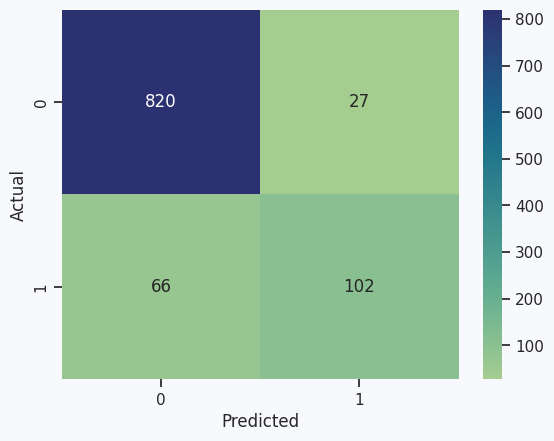

In [ ]:
ada = make_pipe(AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3, random_state=42),
                                   n_estimators=300, learning_rate=0.5, random_state=42))
ada.fit(X_train, y_train)
display(table([evaluate("AdaBoost", ada)]))

sns.heatmap(confusion_matrix(y_test, ada.predict(X_test)), annot=True, fmt="d", cmap="crest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### How does AdaBoost adjust weights for misclassified samples?

After each weak model, the weights of the **wrongly classified samples go up** (then all weights are normalised). **Why:** the next model is forced to focus on the hard examples that the earlier ones got wrong. The final prediction is a weighted vote of all the models.

## 4.3 Hard and soft voting
The voting group contains a linear classifier (`LogisticRegression`), a tree ensemble (`RandomForestClassifier`), and a kernel classifier (`SVC(probability=True)`).

In [ ]:
def estimators():
    return [("lr", LogisticRegression(max_iter=2000, random_state=42)),
            ("rf", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
            ("svc", SVC(probability=True, random_state=42))]

rows = []
for name, est in estimators():
    rows.append(evaluate("member: " + name, make_pipe(est).fit(X_train, y_train)))
for voting in ["hard", "soft"]:
    vote = make_pipe(VotingClassifier(estimators(), voting=voting)).fit(X_train, y_train)
    rows.append(evaluate("Voting " + voting, vote))

display(table(rows))

,train_acc,test_acc,precision,recall,f1,roc_auc
model,,,,,,
member: lr,0.8935,0.8798,0.7500,0.4107,0.5308,0.8640
member: rf,1.0000,0.9665,0.9786,0.8155,0.8896,0.9880
member: svc,0.9017,0.8847,0.8312,0.3810,0.5224,0.9069
Voting hard,0.9197,0.9005,0.8941,0.4524,0.6008,NaN
Voting soft,0.9455,0.9084,0.8571,0.5357,0.6593,0.9624


**Voting approaches compared**
* **Hard:** majority vote of the predicted labels.
* **Soft:** average of the predicted probabilities (needs `predict_proba`, so we use `SVC(probability=True)`). Confident models count more. It usually does better, as the table shows.
* The random forest alone beats both voting models here, because the weaker LR and SVC models pull the vote down.

---
# Model Results and Final Takeaways

,train_acc,test_acc,precision,recall,f1,roc_auc
model,,,,,,
member: rf,1.0000,0.9665,0.9786,0.8155,0.8896,0.9880
Pasting,1.0000,0.9635,0.9068,0.8690,0.8875,0.9826
Bagging,1.0000,0.9616,0.9272,0.8333,0.8777,0.9837
Tree depth=None,1.0000,0.9557,0.8639,0.8690,0.8665,0.9209
AdaBoost,0.9295,0.9084,0.7907,0.6071,0.6869,0.9450
Voting soft,0.9455,0.9084,0.8571,0.5357,0.6593,0.9624
Voting hard,0.9197,0.9005,0.8941,0.4524,0.6008,NaN
Tree depth=6,0.9165,0.8857,0.7167,0.5119,0.5972,0.8896
LogReg No penalty,0.8953,0.8828,0.7094,0.4940,0.5825,0.8748


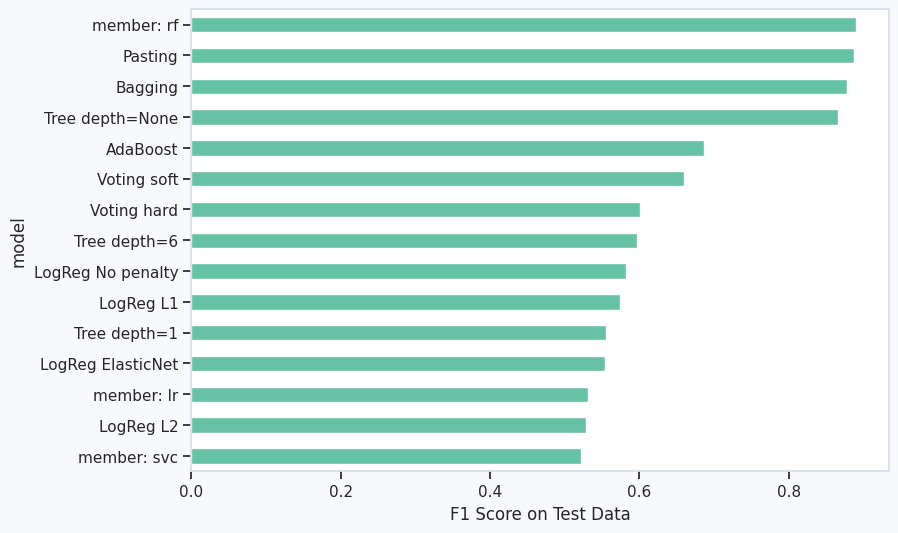

In [ ]:
final = pd.DataFrame(results).set_index("model")
final = final[["train_acc", "test_acc", "precision", "recall", "f1", "roc_auc"]].round(4)
display(final.sort_values("f1", ascending=False))

final["f1"].sort_values().plot(kind="barh", figsize=(9, 6))
plt.xlabel("F1 Score on Test Data")
plt.show()

### Summary
1. **Data:** about 17 % churn. Duplicates, inconsistent labels and missing values were handled. Use F1/recall, not just accuracy.
2. **Pipeline:** all preprocessing is learned from the training data only, with a stratified split (`random_state=42`).
3. **Bias-variance:** the depth-1 tree underfits. The unlimited tree memorises the training set but is still the best single tree on test data.
4. **Regularization:** L2 shrinks coefficients; L1 and Elastic Net also set some to zero. Linear models stay weak because of bias.
5. **Ensembles:** bagging, pasting and the random forest are the best (test F1 about 0.88-0.89). AdaBoost and voting beat the linear models but are behind them.